# **1. Bussines Understanding**

## **1.1 Latar Belakang**

Kesehatan mental mahasiswa dipengaruhi oleh berbagai aspek gaya hidup dan aktivitas akademik. Data ini menggambarkan hasil survei terhadap 10.000 mahasiswa yang mencakup kebiasaan sehari-hari, prestasi belajar, dan kesejahteraan mental sebagai bahan analisis berbasis data.

## **1.2 Tujuan**

Memabangun Machine Learning untuk memprediksi kesehatan mental mahasiswa

## **1.3 Masalah**

Dalam mendeteksi kesehatan mental masih menggunakan metode manual

## **1.4 Tujuan**

Memabangun Machine Learning untuk memprediksi kesehatan mental mahasiswa secara otomatis menggunakan machine learning

In [82]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [83]:
df = pd.read_csv('student_lifestyle_100k.csv')

In [84]:
print('Jumlah Baris :', df.shape[0])
print('================================')
print('Jumlah Kolom :', df.shape[1])
print('================================')
print('5 Data Pertama : ', df.head())

Jumlah Baris : 100000
Jumlah Kolom : 11
5 Data Pertama :     Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  Study_Hours  \
0        1001   22  Female      Science  3.50             7.3          3.3   
1        1002   20    Male  Engineering  2.72             5.5          7.2   
2        1003   20    Male      Medical  3.01             5.4          2.3   
3        1004   21    Male  Engineering  3.63             8.1          2.0   
4        1005   19    Male         Arts  3.14             6.8          2.6   

   Social_Media_Hours  Physical_Activity  Stress_Level  Depression  
0                 3.4                114             5       False  
1                 6.0                142             2       False  
2                 1.8                137             3       False  
3                 4.6                130             3       False  
4                 4.3                  4             6       False  


In [85]:
df.isnull().sum().sum()

np.int64(0)

In [86]:
df.duplicated().sum().sum()

np.int64(0)

In [87]:
print(df.info)
print(df.describe)

<bound method DataFrame.info of        Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  \
0            1001   22  Female      Science  3.50             7.3   
1            1002   20    Male  Engineering  2.72             5.5   
2            1003   20    Male      Medical  3.01             5.4   
3            1004   21    Male  Engineering  3.63             8.1   
4            1005   19    Male         Arts  3.14             6.8   
...           ...  ...     ...          ...   ...             ...   
99995      100996   24  Female      Medical  2.02             7.0   
99996      100997   24    Male         Arts  2.33             5.0   
99997      100998   24  Female  Engineering  2.23             6.5   
99998      100999   19    Male  Engineering  3.61             6.1   
99999      101000   24  Female      Medical  2.10             7.9   

       Study_Hours  Social_Media_Hours  Physical_Activity  Stress_Level  \
0              3.3                 3.4                114       

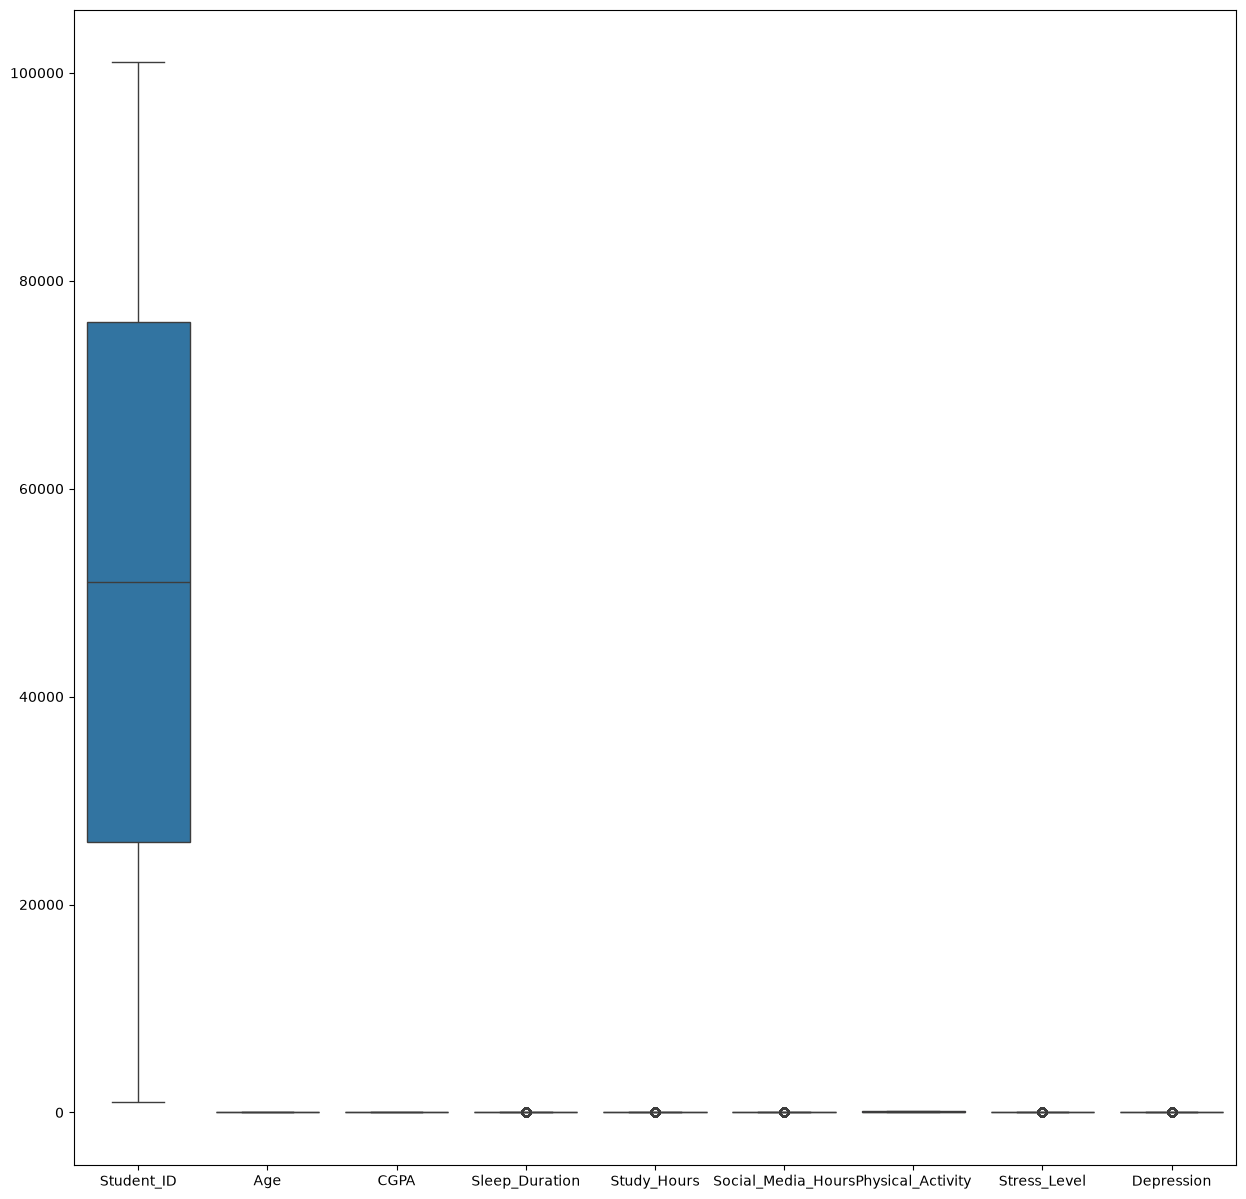

In [88]:
cols = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity', 'Stress_Level', ]

plt.figure(figsize=(15,15))

sns.boxplot(df)
plt.show()

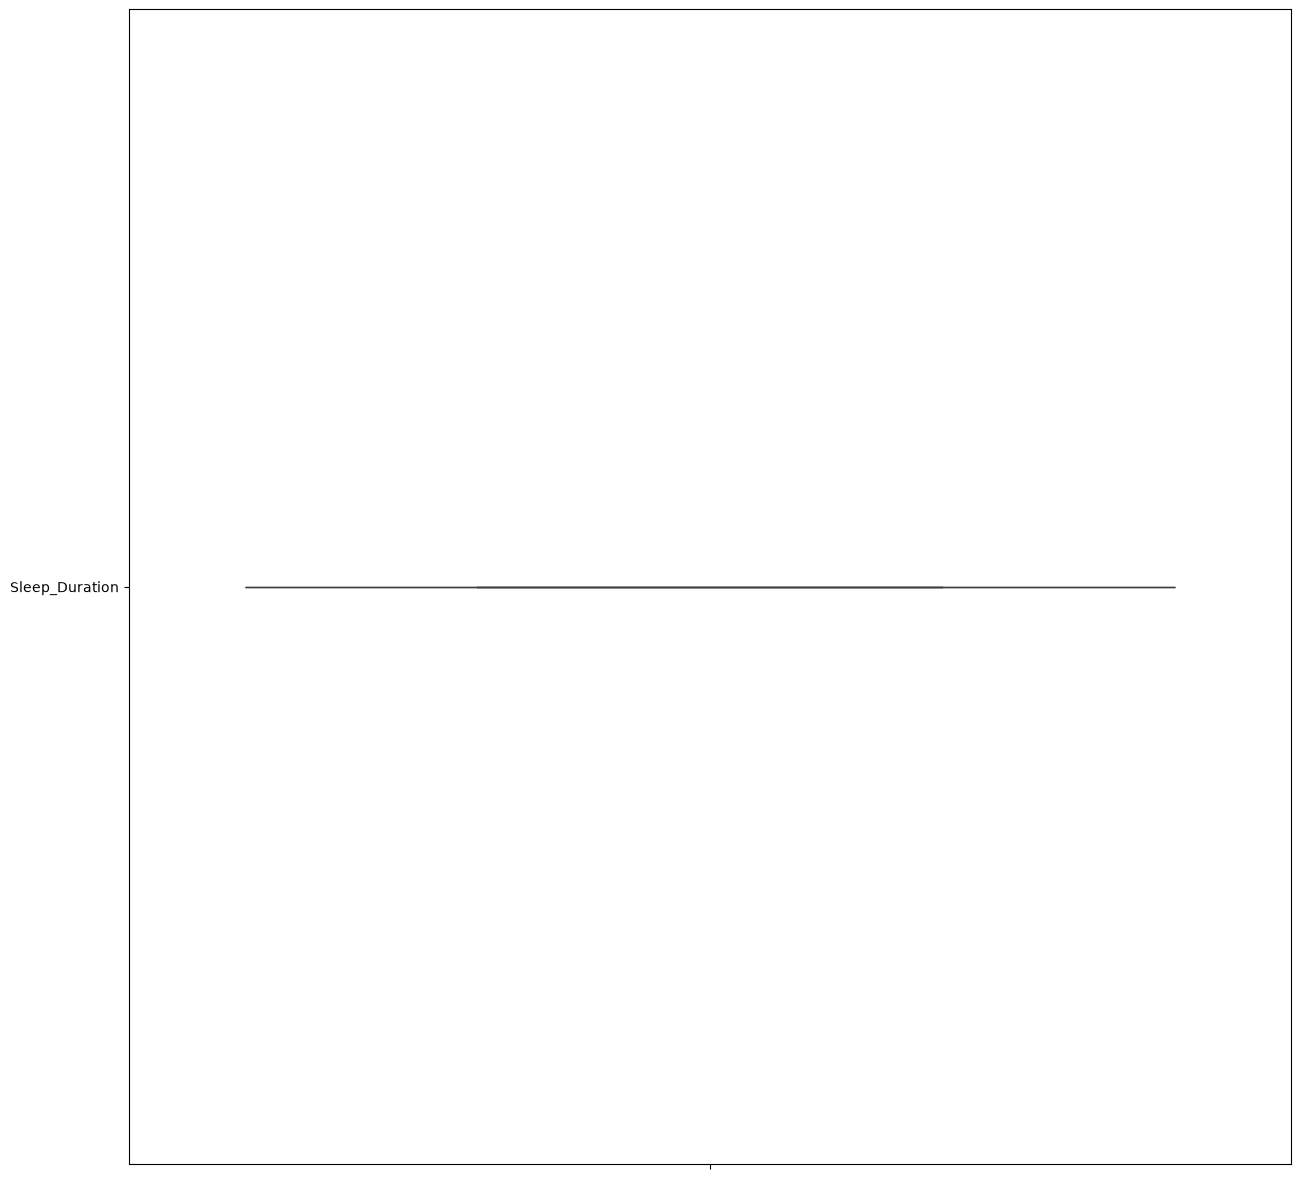

In [89]:
cols = ['Sleep_Duration']

plt.figure(figsize=(15,15))

sns.boxplot(cols)
plt.show()

In [90]:
# cols = df.select_dtypes(include='number')

# Q1 = df.quantile(0.25)
# Q3 = df.quantile(0.25)

# batas_bawah = df.quantile - 1.5
# batas_atas = df.quantile + 1.5

# outlier((batas_bawah <  ))

In [91]:
kolom_teks = df.select_dtypes(include=['string'])

df[kolom_teks] = df[kolom_teks].pd.factorize('int')

TypeError: Boolean array expected for the condition, not str

In [ ]:
corr_spearman = df.corr(method = 'spearman')
corr_spearman


ValueError: could not convert string to float: 'Female'

TypeError: heatmap() missing 1 required positional argument: 'data'

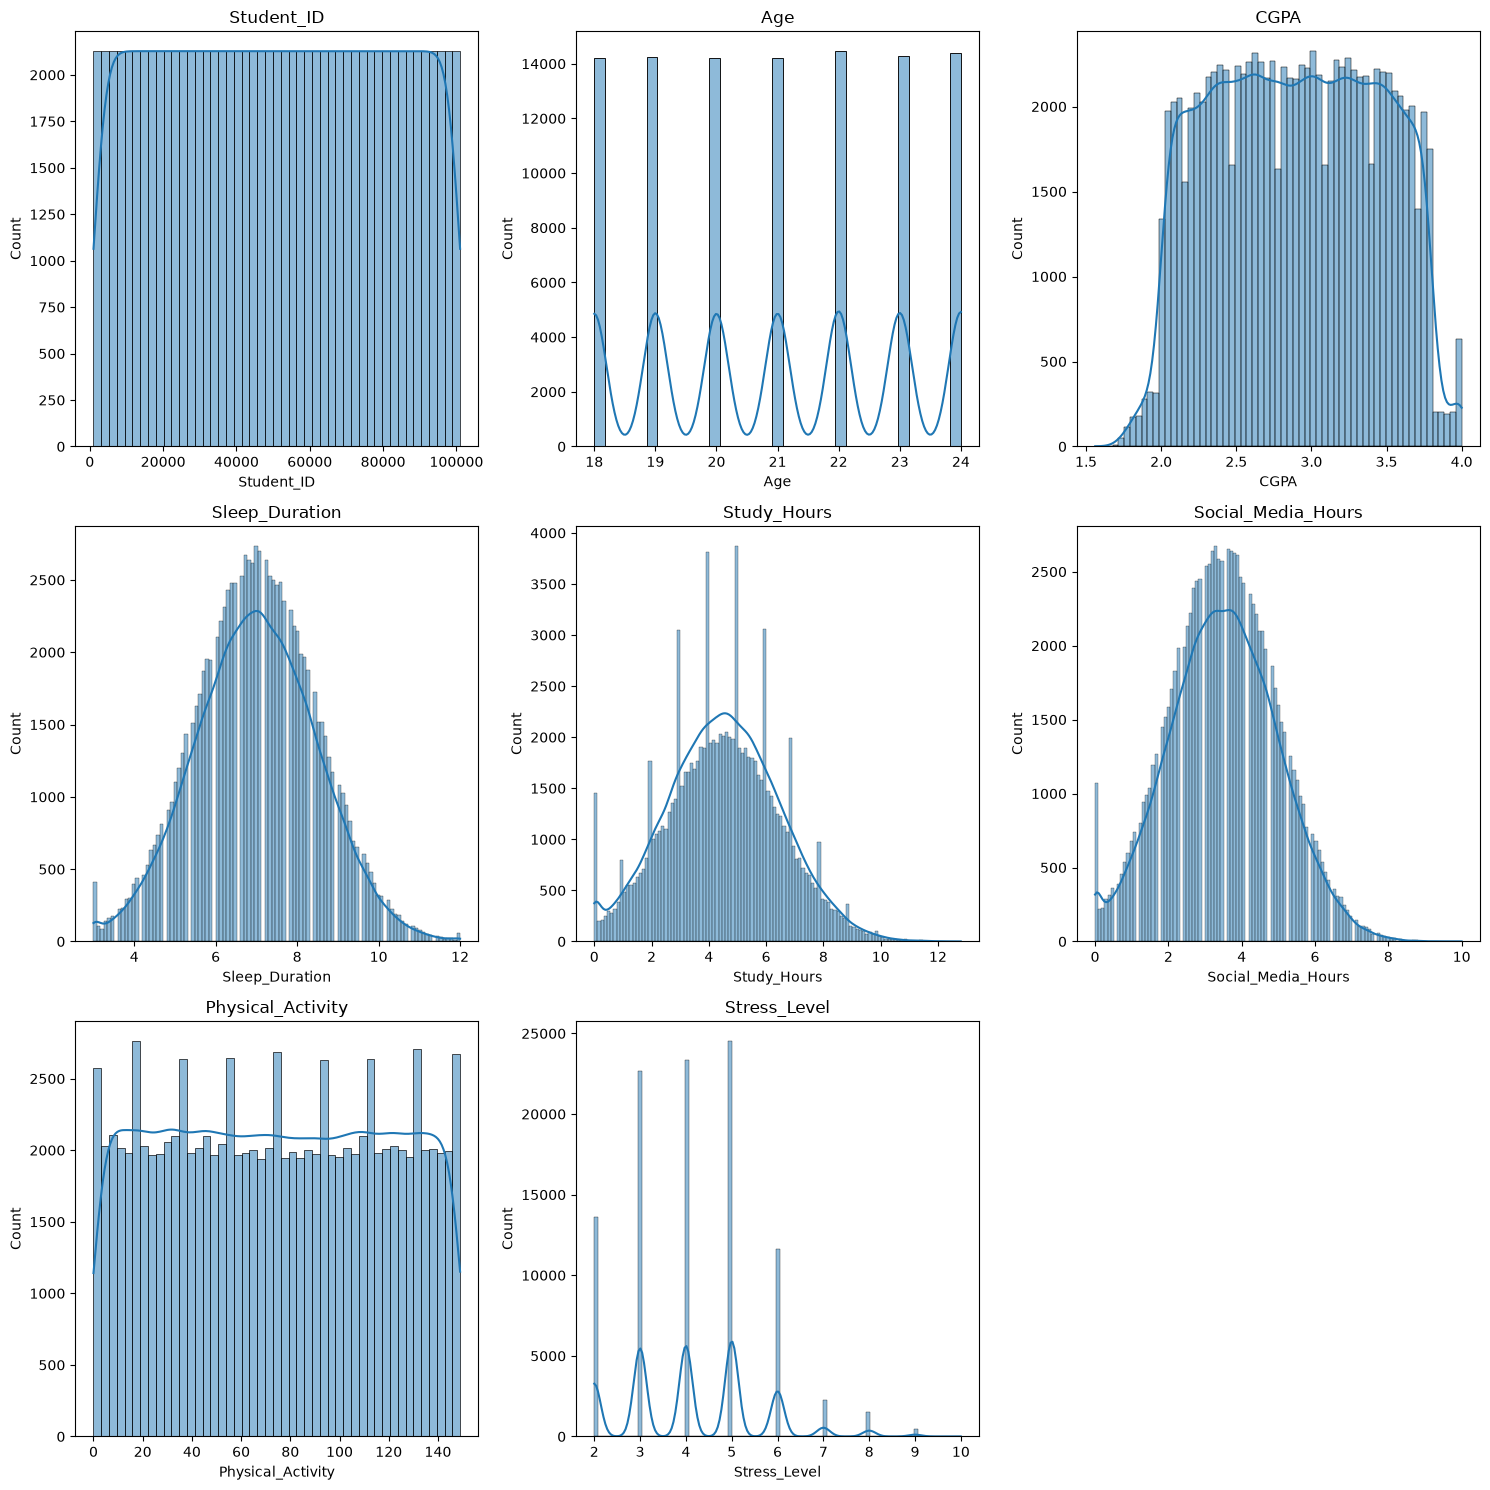

In [ ]:
# ============================================================
# EDA - Histogram Distribusi Fitur Numerik
# ============================================================
# Fungsi      : menampilkan histogram beserta kurva KDE tiap kolom numerik untuk melihat
#               bentuk distribusi data (normal, miring, atau seragam)
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15, 15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 3, i)
    sns.histplot(data=df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()


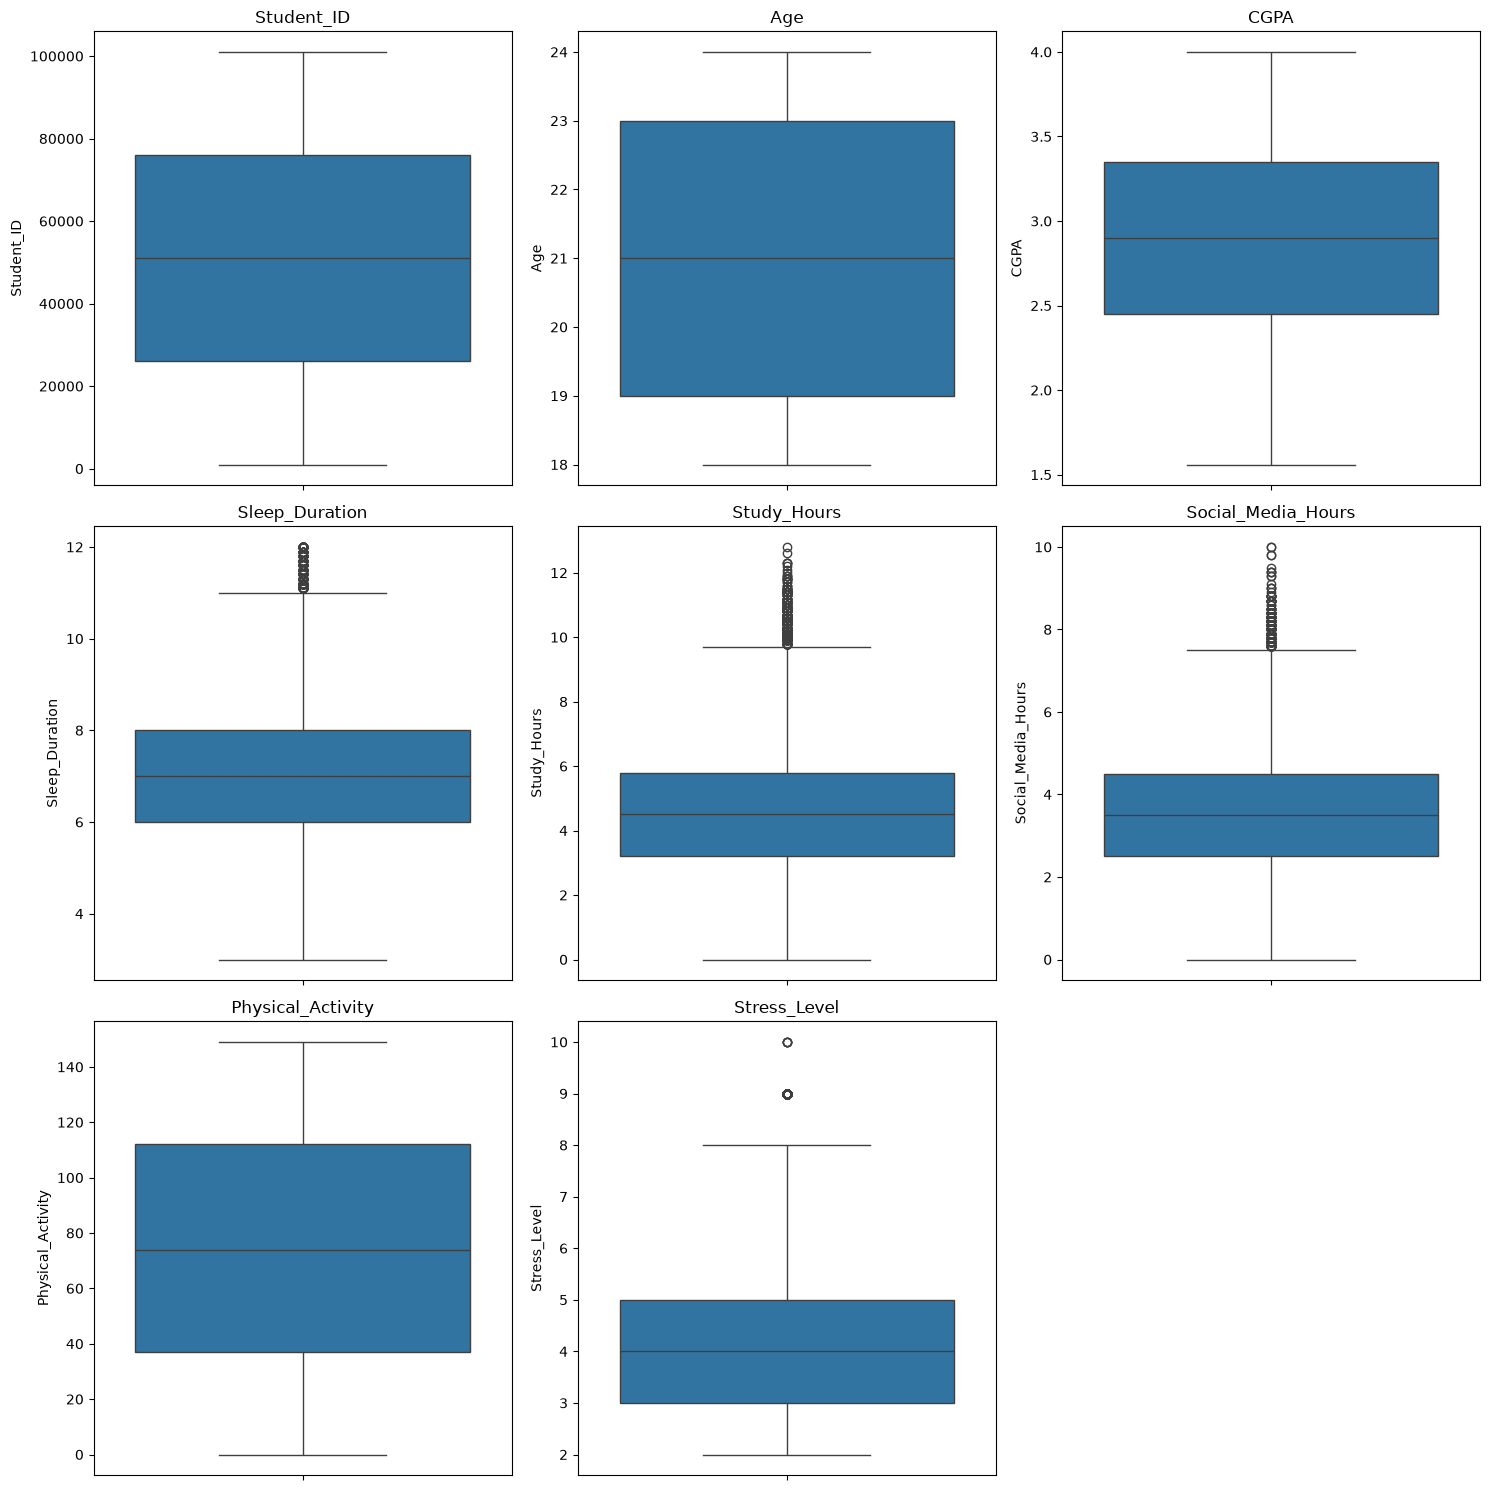

In [94]:
# ============================================================
# EDA - Histogram Distribusi Fitur Numerik
# ============================================================
# Fungsi      : menampilkan histogram beserta kurva KDE tiap kolom numerik untuk melihat
#               bentuk distribusi data (normal, miring, atau seragam)
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15, 15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [ ]:
cols = df.select_dtypes(include=['int64', 'float64'])

Q1 = cols.quantile(0.25)
Q3 = cols.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((cols < batas_bawah) | (cols > batas_atas)).sum()
# print('outlier pada dataset : \n', outlier)
# print('========================================================')
# print('Total outlier : ', outlier.sum())

hasil = pd.DataFrame({'Jumlah Outlier': outlier, 'Persetase Outlier': (outlier/len(df))*100})
hasil.sort_values(by = 'Jumlah Outlier', ascending = False )

,Jumlah Outlier,Persetase Outlier
Stress_Level,478,0.478
Study_Hours,432,0.432
Sleep_Duration,369,0.369
Social_Media_Hours,328,0.328
CGPA,0,0.000
Age,0,0.000
Student_ID,0,0.000
Physical_Activity,0,0.000


In [ ]:
# ============================================================
# Data Preprocessing - Pembuatan Kelas Target Price_Category
# ============================================================
# Fungsi      : membentuk kelas target baru Price_Category dari Selling_Price memakai
#               pd.cut dengan tiga kelas:
#               - Low    : harga kurang dari sama dengan $5.000
#               - Medium : harga $5.001 - $20.000
#               - High   : harga lebih dari $20.000
# Membuat kelas target Price_Category dari Selling_Price
df['Price_Category'] = pd.cut(
    df['Selling_Price'],
    bins=[-np.inf, 5000, 20000, np.inf],
    labels=['Low', 'Medium', 'High']
)

print('Distribusi Price_Category :')
print('========================================================')
print(df['Price_Category'].value_counts())

# Kesimpulan  : ketiga kelas terbentuk dengan jumlah Medium 2.125, Low 2.091, dan
#               High 1.284 baris. Distribusinya cukup merata, meskipun kelas High paling
#               sedikit karena harga di atas $20.000 memang lebih jarang.

In [ ]:
# ============================================================
# EDA - Penanganan Outlier: IQR (Winsorizing / Capping)
# ============================================================
# Fungsi      : menarik nilai ekstrem setiap fitur numerik ke batas IQR terdekat
#               (capping / winsorizing) tanpa menghapus baris.
#               Outlier tidak dihapus karena nilai ekstrem (mis. Mileage tinggi pada
#               mobil tua) masih valid dan penting sebagai sinyal harga.
#               Catatan: kolom target Selling_Price TIDAK di-capping agar variasi
#               harga asli tetap utuh untuk model regresi.

kolom_capping = cols.columns.drop('Selling_Price')
batas_bawah_cap = batas_bawah[kolom_capping]
batas_atas_cap = batas_atas[kolom_capping]

outlier_sebelum = ((df[kolom_capping] < batas_bawah_cap) | (df[kolom_capping] > batas_atas_cap)).sum()

for col in kolom_capping:
    df[col] = df[col].clip(lower=batas_bawah_cap[col], upper=batas_atas_cap[col])

outlier_sesudah = ((df[kolom_capping] < batas_bawah_cap) | (df[kolom_capping] > batas_atas_cap)).sum()

ringkasan = pd.DataFrame({
    'Outlier Sebelum': outlier_sebelum,
    'Outlier Sesudah': outlier_sesudah
})

print('Total outlier sebelum capping :', outlier_sebelum.sum())
print('Total outlier sesudah capping :', outlier_sesudah.sum())
print('========================================================')
print(ringkasan)

# Kesimpulan  : jumlah outlier pada fitur numerik turun dari 1.166 menjadi 0, sementara
#               jumlah baris tetap 5.500 dan rentang harga asli (500 - 86.692 USD)
#               tidak berubah karena kolom target tidak ikut di-capping.

In [ ]:
# ============================================================
# EDA - Heatmap Korelasi Fitur Numerik
# ============================================================
# Fungsi      : menghitung matriks korelasi antar kolom numerik lalu menampilkannya
#               sebagai heatmap untuk melihat arah dan kekuatan hubungan antar fitur
# Korelasi antar fitur numerik dan target Selling_Price
plt.figure(figsize=(10, 8))

sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Heatmap Korelasi Fitur Numerik')
plt.tight_layout()
plt.show()

# Kesimpulan  : Year berkorelasi positif paling kuat terhadap Selling_Price (+0.81),
#               sedangkan Mileage (-0.68), Owners (-0.67), dan Accident_History (-0.39)
#               berkorelasi negatif. Fitur lain seperti Engine_Size, Horsepower, Torque,
#               dan Fuel_Efficiency korelasinya lemah (di bawah 0.13).